# Building a constrained hedge

A symmetric covariance matrix has an orthonormal eigenvector basis in which portfolio variance is a weighted sum of squared component exposures:

$$
\Sigma=V\Lambda V^{\mathsf T},
\qquad
w^{\mathsf T}\Sigma w=\sum_{k=1}^{N}\lambda_k z_k^2,
\qquad
z=V^{\mathsf T}w.
$$

Here, $\Sigma$ is the covariance matrix for $N$ assets, $V$ contains $N$ orthonormal eigenvectors, $\Lambda$ is diagonal with eigenvalues $\lambda_k$, $k$ labels a component from $1$ through $N$, $w$ is an asset-weight vector, and $z_k$ is its exposure to principal component $k$.

,Field,Value
0,Provider,Kenneth R. French Data Library
1,Return type,Daily value-weighted return
2,Analysis start,2019-01-02
3,Analysis end,2025-12-31
4,Complete dates,1760
5,Selected industries,16
6,Selection rule,"First 16 industries in archive order, fixed be..."


,Component,Eigenvalue,Explained variance share,Cumulative variance share
0,1,0.595064,0.565847,0.565847
1,2,0.093793,0.089187,0.655035
2,3,0.077477,0.073673,0.728707
3,4,0.052096,0.049538,0.778245
4,5,0.042011,0.039948,0.818194
5,6,0.033357,0.031719,0.849912
6,7,0.032707,0.031101,0.881013
7,8,0.024809,0.023591,0.904604
8,9,0.022124,0.021038,0.925642
9,10,0.020536,0.019527,0.94517


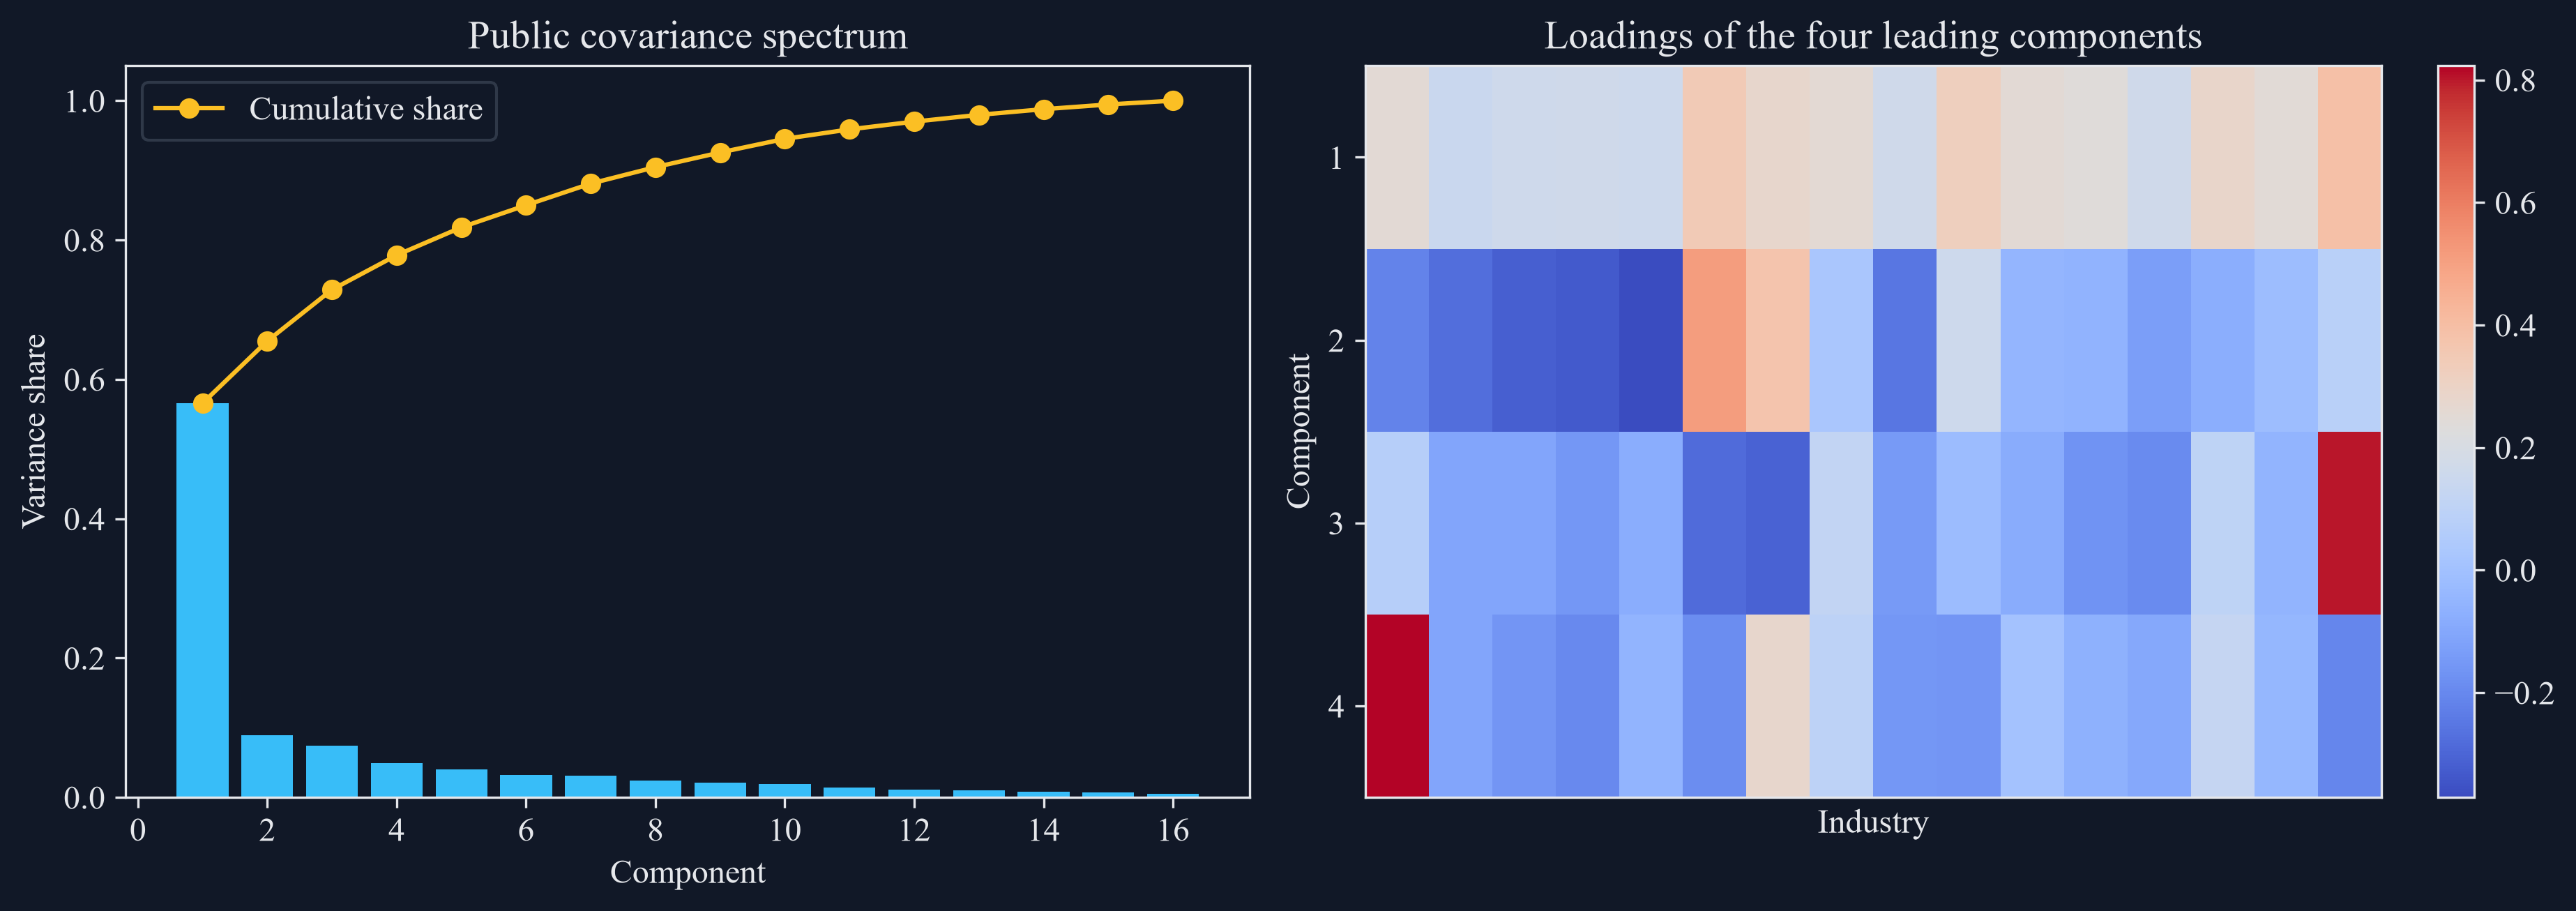

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display

def compact_float_format(number_format=None):

    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value

def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch('[+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?', rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return '0'
    if ('.' in rendered or 'e' in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered

def compact_numeric_text(text):
    pattern = '(?<![0-9.eE])([+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])'
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)

def compact_table_latex(latex):
    return compact_numeric_text(latex)

def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + '</div>'

def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)
from pathlib import Path
import sys
import time
import warnings
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import io
import zipfile
DATA_URL = 'https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/49_Industry_Portfolios_daily_CSV.zip'
DATA_DIR = ROOT / 'data' / 'public' / 'ken_french'
DATA_PATH = ensure_dataset(ROOT, 'french_49_industries')
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
with zipfile.ZipFile(DATA_PATH) as archive:
    archive_name = archive.namelist()[0]
    public_lines = archive.read(archive_name).decode('latin1').splitlines()
header_row = next((index for index, line in enumerate(public_lines) if line.startswith(',Agric')))
end_row = next((index for index in range(header_row + 1, len(public_lines)) if not public_lines[index].strip()))
raw = pd.read_csv(io.StringIO('\n'.join(public_lines[header_row:end_row])))
raw = raw.rename(columns={raw.columns[0]: 'Date'})
raw['Date'] = pd.to_datetime(raw['Date'].astype(str), format='%Y%m%d')
raw = raw.set_index('Date').replace([-99.99, -999.0], np.nan) / 100.0
industry_returns = raw.loc['2019-01-01':'2025-12-31'].dropna().copy()
from RiskLabAI.cluster.clustering import cluster_k_means_base, covariance_to_correlation
from RiskLabAI.data.denoise.denoising import denoise_cov
from RiskLabAI.hpc.hpc import parallel_run
from RiskLabAI.optimization.hedging import pca_weights
from RiskLabAI.optimization.hrp import hrp
from RiskLabAI.optimization.nco import get_optimal_portfolio_weights, get_optimal_portfolio_weights_nco
FIGURES = ROOT / 'outputs' / 'figures' / '26_nested_cluster_optimization'
TABLES = ROOT / 'outputs' / 'tables' / '26_nested_cluster_optimization'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
palette = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151', 'muted': '#94A3B8'}
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': palette['background'], 'axes.facecolor': palette['axes'], 'axes.edgecolor': palette['text'], 'axes.labelcolor': palette['text'], 'axes.titlecolor': palette['text'], 'xtick.color': palette['text'], 'ytick.color': palette['text'], 'text.color': palette['text'], 'grid.color': palette['grid'], 'grid.linestyle': ':', 'legend.facecolor': palette['axes'], 'legend.edgecolor': palette['grid'], 'savefig.facecolor': palette['background']})

def display_float(value):
    if not np.isfinite(value):
        return str(value)
    nearest_integer = round(float(value))
    if np.isclose(value, nearest_integer, atol=1e-12):
        return str(int(nearest_integer))
    if abs(value) < 5e-13:
        return '0'
    return f'{value:.6f}'.rstrip('0').rstrip('.')
pd.set_option('display.float_format', display_float)

def save_table(frame, stem, caption, label, float_format='%.6f', fit=True, position='tbp'):
    frame.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position=position))
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{adjustbox}{max width=\\textwidth}' + '\n' + '\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}' + '\n' + '\\end{adjustbox}', 1)
    else:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{tabular}', 1)
    latex = latex.replace('nan', 'Not available').replace('NaN', 'Not available').replace('inf', 'No finite value')
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')

def save_figure(figure, stem):
    figure.savefig(FIGURES / f'{stem}.png', bbox_inches='tight', dpi=300)
    figure.savefig(FIGURES / f'{stem}.pdf', bbox_inches='tight')
    display(Image(filename=str(FIGURES / f'{stem}.png')))
    plt.close(figure)

def correlation_frame(covariance):
    frame = covariance if isinstance(covariance, pd.DataFrame) else pd.DataFrame(covariance)
    values = covariance_to_correlation(frame.to_numpy(dtype=float))
    return pd.DataFrame(values, index=frame.index, columns=frame.columns)

def optimal_series(covariance, mean=None):
    frame = covariance if isinstance(covariance, pd.DataFrame) else pd.DataFrame(covariance)
    mean_values = None if mean is None else np.asarray(mean, dtype=float).reshape(-1, 1)
    values = get_optimal_portfolio_weights(frame.to_numpy(dtype=float), mean_values).flatten()
    return pd.Series(values, index=frame.index, dtype=float)

def nco_components(covariance, mean=None, maximum_clusters=4, seed=2201):
    frame = covariance if isinstance(covariance, pd.DataFrame) else pd.DataFrame(covariance)
    correlation = correlation_frame(frame)
    mean_series = None if mean is None else pd.Series(np.asarray(mean, dtype=float).flatten(), index=frame.index)
    np.random.seed(seed)
    sorted_correlation, clusters, silhouette = cluster_k_means_base(correlation, max_clusters=maximum_clusters, iterations=10)
    within = pd.DataFrame(0.0, index=frame.index, columns=sorted(clusters))
    for cluster_id, members in clusters.items():
        local_mean = None if mean_series is None else mean_series.loc[members].to_numpy().reshape(-1, 1)
        within.loc[members, cluster_id] = get_optimal_portfolio_weights(frame.loc[members, members].to_numpy(), local_mean).flatten()
    reduced_covariance = within.T.dot(frame.dot(within))
    reduced_mean = None if mean_series is None else within.T.dot(mean_series).to_numpy().reshape(-1, 1)
    between = pd.Series(get_optimal_portfolio_weights(reduced_covariance.to_numpy(), reduced_mean).flatten(), index=reduced_covariance.index)
    final = within.mul(between, axis=1).sum(axis=1)
    return {'correlation': correlation, 'sorted_correlation': sorted_correlation, 'clusters': clusters, 'silhouette': silhouette, 'within': within, 'reduced_covariance': reduced_covariance, 'between': between, 'final': final}

def released_nco(covariance, mean=None, maximum_clusters=4, seed=2201):
    frame = covariance if isinstance(covariance, pd.DataFrame) else pd.DataFrame(covariance)
    mean_values = None if mean is None else np.asarray(mean, dtype=float).reshape(-1, 1)
    np.random.seed(seed)
    values = get_optimal_portfolio_weights_nco(frame.to_numpy(dtype=float), mean_values, number_clusters=maximum_clusters).flatten()
    return pd.Series(values, index=frame.index, dtype=float)

def inverse_variance_series(covariance):
    frame = covariance if isinstance(covariance, pd.DataFrame) else pd.DataFrame(covariance)
    values = 1.0 / np.diag(frame.to_numpy(dtype=float))
    return pd.Series(values / values.sum(), index=frame.index)

def hrp_series(covariance):
    frame = covariance if isinstance(covariance, pd.DataFrame) else pd.DataFrame(covariance)
    return hrp(frame, correlation_frame(frame)).reindex(frame.index)

def portfolio_variance(weights, covariance):
    frame = covariance if isinstance(covariance, pd.DataFrame) else pd.DataFrame(covariance)
    vector = pd.Series(weights, index=frame.index).reindex(frame.index).to_numpy(dtype=float)
    return float(vector @ frame.to_numpy(dtype=float) @ vector)

def portfolio_statistics(name, weights, covariance):
    frame = covariance if isinstance(covariance, pd.DataFrame) else pd.DataFrame(covariance)
    vector = pd.Series(weights, index=frame.index).reindex(frame.index).to_numpy(dtype=float)
    variance = float(vector @ frame.to_numpy(dtype=float) @ vector)
    concentration = float(vector @ vector)
    return {'Portfolio': name, 'Annual volatility': float(np.sqrt(variance)), 'Net exposure': float(vector.sum()), 'Gross exposure': float(np.abs(vector).sum()), 'Smallest weight': float(vector.min()), 'Largest weight': float(vector.max()), 'Effective holdings': float(1.0 / concentration)}

def block_covariance(blocks, block_size, within_correlation, between_correlation=0.03):
    asset_count = blocks * block_size
    correlation = np.full((asset_count, asset_count), between_correlation, dtype=float)
    for block in range(blocks):
        start = block * block_size
        stop = start + block_size
        correlation[start:stop, start:stop] = within_correlation
    np.fill_diagonal(correlation, 1.0)
    scales = np.linspace(0.1, 0.22, asset_count)
    covariance = correlation * np.outer(scales, scales)
    labels = [f'Asset {index + 1}' for index in range(asset_count)]
    return (pd.DataFrame(covariance, index=labels, columns=labels), pd.DataFrame(correlation, index=labels, columns=labels))

def one_way_turnover(current, previous):
    current_values = pd.Series(current).sort_index().to_numpy(dtype=float)
    previous_values = pd.Series(previous).sort_index().to_numpy(dtype=float)
    return float(0.5 * np.abs(current_values - previous_values).sum())
display_industry_names = {'Agric': 'Agriculture', 'Food': 'Food products', 'Soda': 'Soft drinks', 'Beer': 'Beer and liquor', 'Smoke': 'Tobacco', 'Toys': 'Recreation', 'Fun': 'Entertainment', 'Books': 'Printing and publishing', 'Hshld': 'Household products', 'Clths': 'Apparel', 'Hlth': 'Health care', 'MedEq': 'Medical equipment', 'Drugs': 'Pharmaceutical products', 'Chems': 'Chemicals', 'Rubbr': 'Rubber and plastic products', 'Txtls': 'Textiles'}
selected_assets = list(industry_returns.columns[:16])
public_sample = industry_returns[selected_assets].rename(columns=display_industry_names).copy()
public_covariance = public_sample.cov() * 252.0
public_correlation = public_sample.corr()
public_provenance = pd.DataFrame({'Field': ['Provider', 'Return type', 'Analysis start', 'Analysis end', 'Complete dates', 'Selected industries', 'Selection rule'], 'Value': ['Kenneth R. French Data Library', 'Daily value-weighted return', str(public_sample.index.min().date()), str(public_sample.index.max().date()), len(public_sample), len(selected_assets), 'First 16 industries in archive order, fixed before analysis']})
public_values = public_covariance.to_numpy(dtype=float)
ascending_values, ascending_vectors = np.linalg.eigh(public_values)
descending_order = np.argsort(ascending_values)[::-1]
eigenvalues = ascending_values[descending_order]
raw_eigenvectors = ascending_vectors[:, descending_order]
eigenvectors = raw_eigenvectors.copy()
for component in range(eigenvectors.shape[1]):
    anchor = int(np.argmax(np.abs(eigenvectors[:, component])))
    if eigenvectors[anchor, component] < 0.0:
        eigenvectors[:, component] = -eigenvectors[:, component]
explained_variance = eigenvalues / eigenvalues.sum()
cumulative_variance = np.cumsum(explained_variance)
spectrum_table = pd.DataFrame({'Component': np.arange(1, len(eigenvalues) + 1), 'Eigenvalue': eigenvalues, 'Explained variance share': explained_variance, 'Cumulative variance share': cumulative_variance})
hedge_provenance = public_provenance.copy()
save_table(hedge_provenance, 'hedge_data_provenance', 'Public data used for the Chapter 22 hedge calculations.', 'tab:chapter22-hedge-data')
save_table(spectrum_table, 'public_pca_spectrum', 'Principal-component spectrum of the public industry covariance matrix.', 'tab:chapter22-pca-spectrum')
display(hedge_provenance)
display(spectrum_table)
figure, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))
axes[0].bar(spectrum_table['Component'], spectrum_table['Explained variance share'], color=palette['cyan'])
axes[0].plot(spectrum_table['Component'], spectrum_table['Cumulative variance share'], color=palette['amber'], marker='o', label='Cumulative share')
axes[0].set_title('Public covariance spectrum')
axes[0].set_xlabel('Component')
axes[0].set_ylabel('Variance share')
axes[0].legend()
leading_loadings = pd.DataFrame(eigenvectors[:, :4], index=public_covariance.index, columns=[f'Component {index}' for index in range(1, 5)])
image = axes[1].imshow(leading_loadings.to_numpy(dtype=float).T, cmap='coolwarm', aspect='auto')
axes[1].set_title('Loadings of the four leading components')
axes[1].set_xlabel('Industry')
axes[1].set_ylabel('Component')
axes[1].set_yticks(range(4))
axes[1].set_yticklabels(range(1, 5))
axes[1].set_xticks([])
figure.colorbar(image, ax=axes[1], fraction=0.046)
figure.tight_layout()
save_figure(figure, 'public_pca_spectrum_loadings')
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': '#111827', 'axes.facecolor': '#111827', 'axes.edgecolor': '#94A3B8', 'axes.labelcolor': '#E5E7EB', 'axes.titlecolor': '#E5E7EB', 'axes.titleweight': 'bold', 'xtick.color': '#94A3B8', 'ytick.color': '#94A3B8', 'text.color': '#E5E7EB', 'grid.color': '#374151', 'grid.linestyle': ':', 'grid.linewidth': 0.8, 'legend.facecolor': '#111827', 'legend.edgecolor': '#374151', 'legend.framealpha': 0.96, 'savefig.facecolor': '#111827', 'savefig.transparent': False, 'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == '3.2.0'


## Risk Targets in Principal Coordinates

A component-risk distribution produces asset weights by scaling each eigenvector inversely with the square root of its eigenvalue:

$$
w=V\left(s\sqrt{\rho_1/\lambda_1},\ldots,s\sqrt{\rho_N/\lambda_N}\right)^{\mathsf T},
\qquad
\rho_k\geq0,
\qquad
\sum_{k=1}^{N}\rho_k=1.
$$

Here, $s$ is the target portfolio standard deviation, $\rho_k$ is the target share of variance assigned to component $k$, $\lambda_k$ is that component's eigenvalue, $N$ is the number of assets and components, and $V$ maps component exposures back to asset weights. Each eigenvector is given a fixed orientation by making its largest absolute loading positive. This rule affects the signs of weights and net exposure, but not variance, gross exposure, or component-risk shares.

,Basket,Target standard deviation,Realized standard deviation,Net exposure,Gross exposure,Active components,Largest component variance share
0,Leading component,0.1,0.1,0.496472,0.496472,1,1
1,Equal component risk,0.1,0.1,0.049346,2.130108,16,0.0625
2,Smallest component,0.1,0.1,0.174582,2.585178,1,1


,Basket,Industry,Weight
0,Leading component,Agriculture,0.032345
1,Leading component,Food products,0.018603
2,Leading component,Soft drinks,0.020919
3,Leading component,Beer and liquor,0.021583
4,Leading component,Tobacco,0.020677
5,Leading component,Recreation,0.044738
6,Leading component,Entertainment,0.035971
7,Leading component,Printing and publishing,0.033104
8,Leading component,Household products,0.021759
9,Leading component,Apparel,0.04174


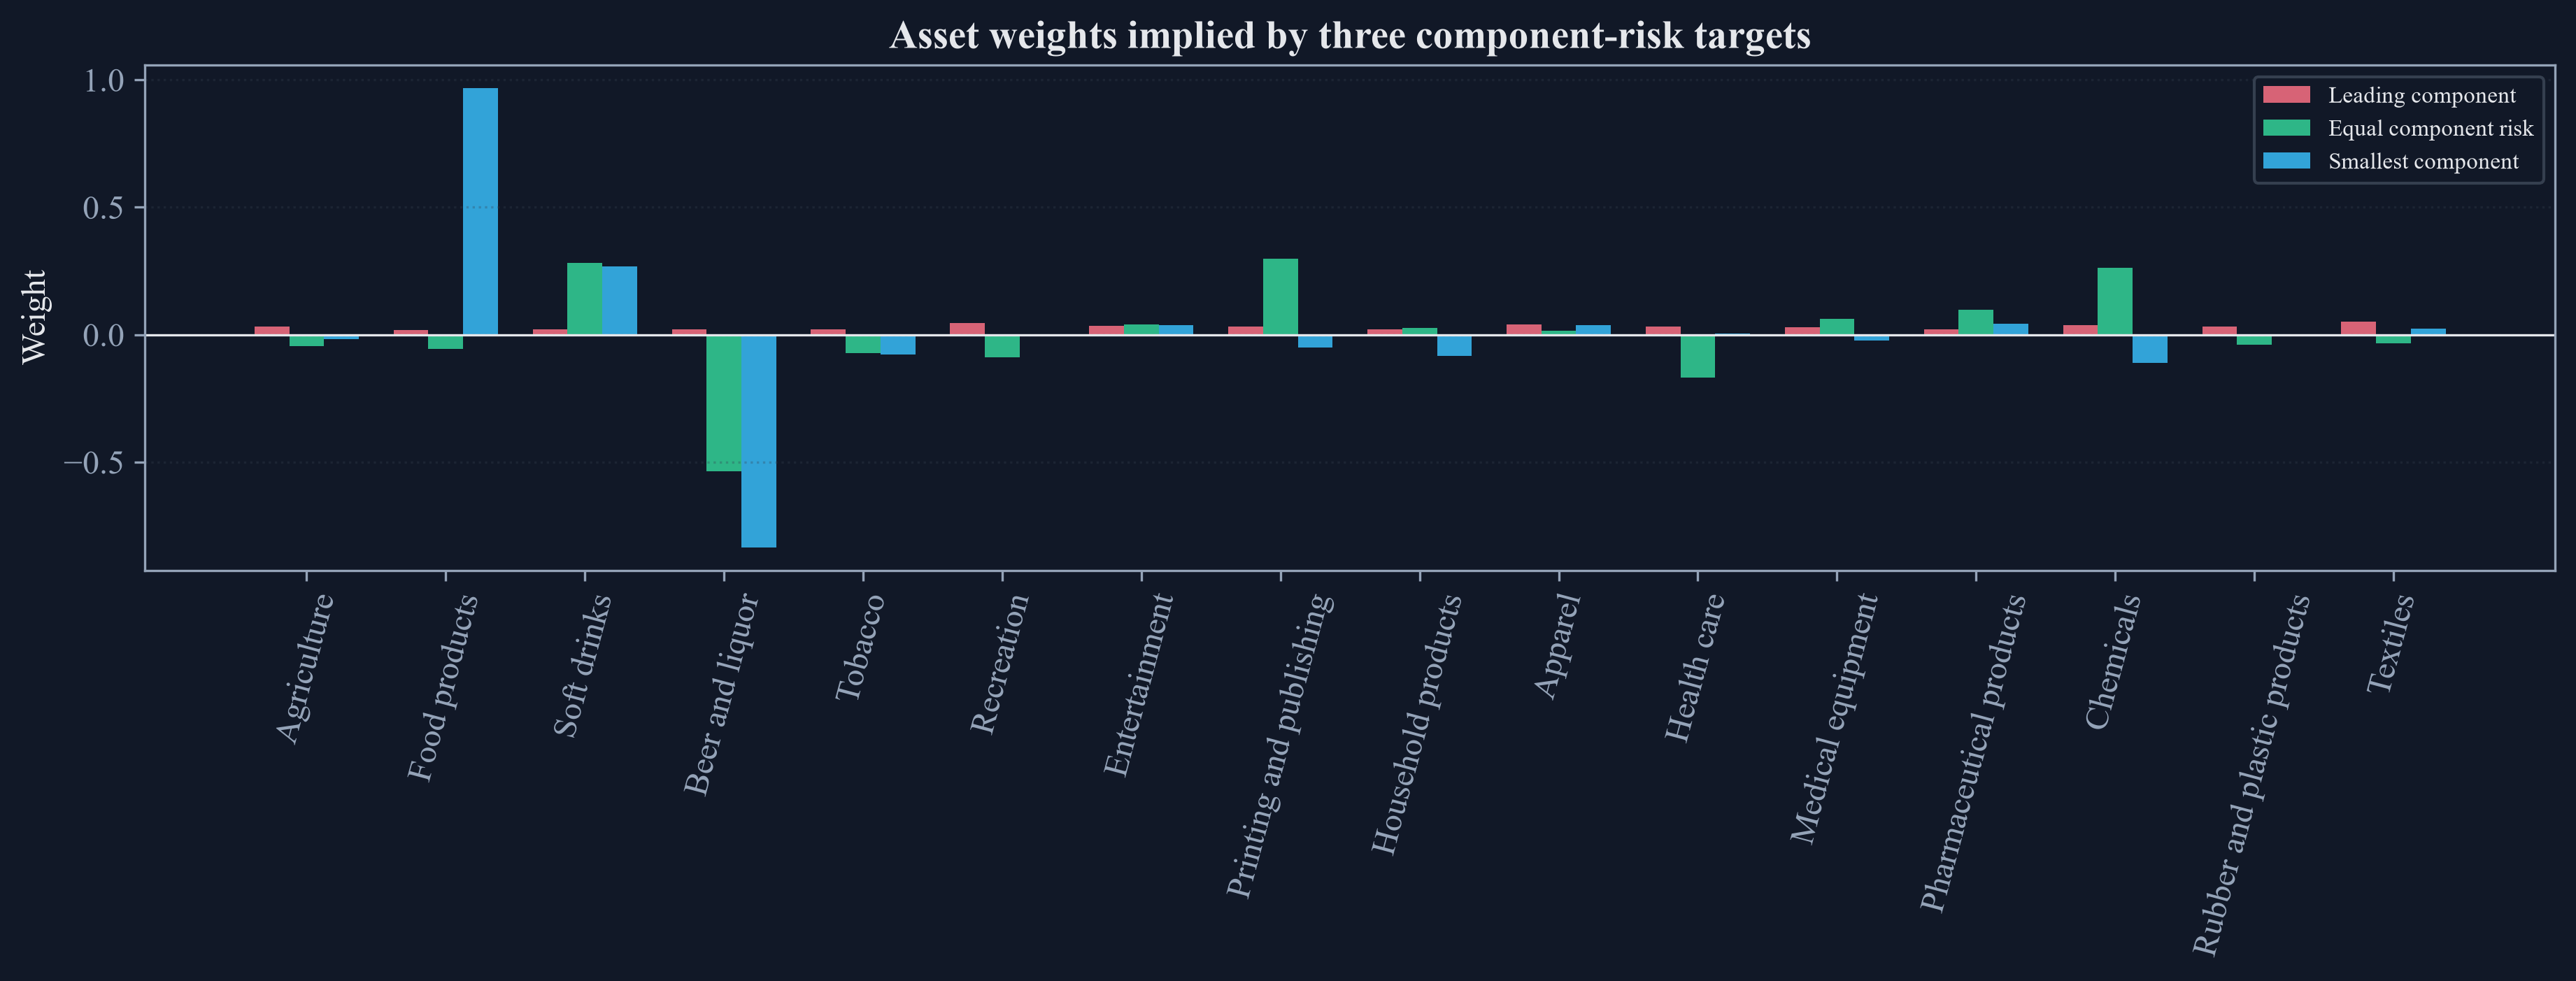

In [2]:
target_standard_deviation = 0.10
component_count = len(public_covariance)
risk_distributions = {"Leading component": np.r_[1.0, np.zeros(component_count - 1)], "Equal component risk": np.repeat(1.0 / component_count, component_count), "Smallest component": np.r_[np.zeros(component_count - 1), 1.0]}
library_pca_baskets = {name: pd.Series(pca_weights(public_values, distribution, risk_target=target_standard_deviation), index=public_covariance.index) for name, distribution in risk_distributions.items()}
pca_baskets = {name: pd.Series(eigenvectors @ (target_standard_deviation * np.sqrt(distribution / eigenvalues)), index=public_covariance.index) for name, distribution in risk_distributions.items()}
target_rows = []
weight_rows = []
for name, weights in pca_baskets.items():
    component_exposure = eigenvectors.T @ weights.to_numpy(dtype=float)
    component_variance = eigenvalues * component_exposure ** 2
    for asset, weight in weights.items():
        weight_rows.append({"Basket": name, "Industry": asset, "Weight": weight})
    target_rows.append({"Basket": name, "Target standard deviation": target_standard_deviation, "Realized standard deviation": np.sqrt(portfolio_variance(weights, public_covariance)), "Net exposure": float(weights.sum()), "Gross exposure": float(np.abs(weights).sum()), "Active components": int(np.count_nonzero(risk_distributions[name])), "Largest component variance share": float(component_variance.max() / component_variance.sum())})
pca_target_summary = pd.DataFrame(target_rows)
pca_weight_table = pd.DataFrame(weight_rows)
pca_target_book_summary = pca_target_summary[["Basket", "Realized standard deviation", "Net exposure", "Gross exposure", "Active components", "Largest component variance share"]]
save_table(pca_target_book_summary, "pca_risk_target_summary", "Risk targets and exposures for three principal-component baskets.", "tab:chapter22-pca-targets")
save_table(pca_weight_table, "pca_weight_profiles", "Asset weights for three principal-component risk distributions.", "tab:chapter22-pca-weights")
display(pca_target_summary)
display(pca_weight_table)

figure, axis = plt.subplots(figsize=(12.5, 4.8))
width = 0.25
positions = np.arange(component_count)
for offset, (name, color) in enumerate(zip(pca_baskets, [palette["rose"], palette["green"], palette["cyan"]])):
    axis.bar(positions + (offset - 1) * width, pca_baskets[name].to_numpy(dtype=float), width=width, label=name, color=color, alpha=0.85)
axis.set_xticks(positions)
axis.set_xticklabels(public_covariance.index, rotation=75)
axis.set_ylabel("Weight")
axis.set_title("Asset weights implied by three component-risk targets")
axis.axhline(0.0, color=palette["text"], linewidth=0.8)
axis.legend(fontsize=8)
axis.grid(axis="y", alpha=0.3)
figure.tight_layout()
save_figure(figure, "pca_weight_profiles")

## Component Exposures

The share of portfolio variance assigned to component $k$ is obtained from its eigenvalue and component exposure:

$$
\operatorname{PCRS}_k=\frac{\lambda_k z_k^2}{\sum_{j=1}^{N}\lambda_j z_j^2}.
$$

Here, $z_k=v_k^{\mathsf T}w$ is exposure to eigenvector $v_k$, $\lambda_k$ is its eigenvalue, $j$ indexes every component in the denominator, $N$ is the number of components, and $\operatorname{PCRS}_k$ is the principal-component risk share.

,Basket,Component,Eigenvalue,Component exposure,Variance contribution,Variance share
0,Leading component,1,0.595064,0.129634,0.01,1
1,Leading component,2,0.093793,0,0,0
2,Leading component,3,0.077477,0,0,0
3,Leading component,4,0.052096,0,0,0
4,Leading component,5,0.042011,0,0,0
5,Leading component,6,0.033357,0,0,0
6,Leading component,7,0.032707,0,0,0
7,Leading component,8,0.024809,0,0,0
8,Leading component,9,0.022124,0,0,0
9,Leading component,10,0.020536,0,0,0


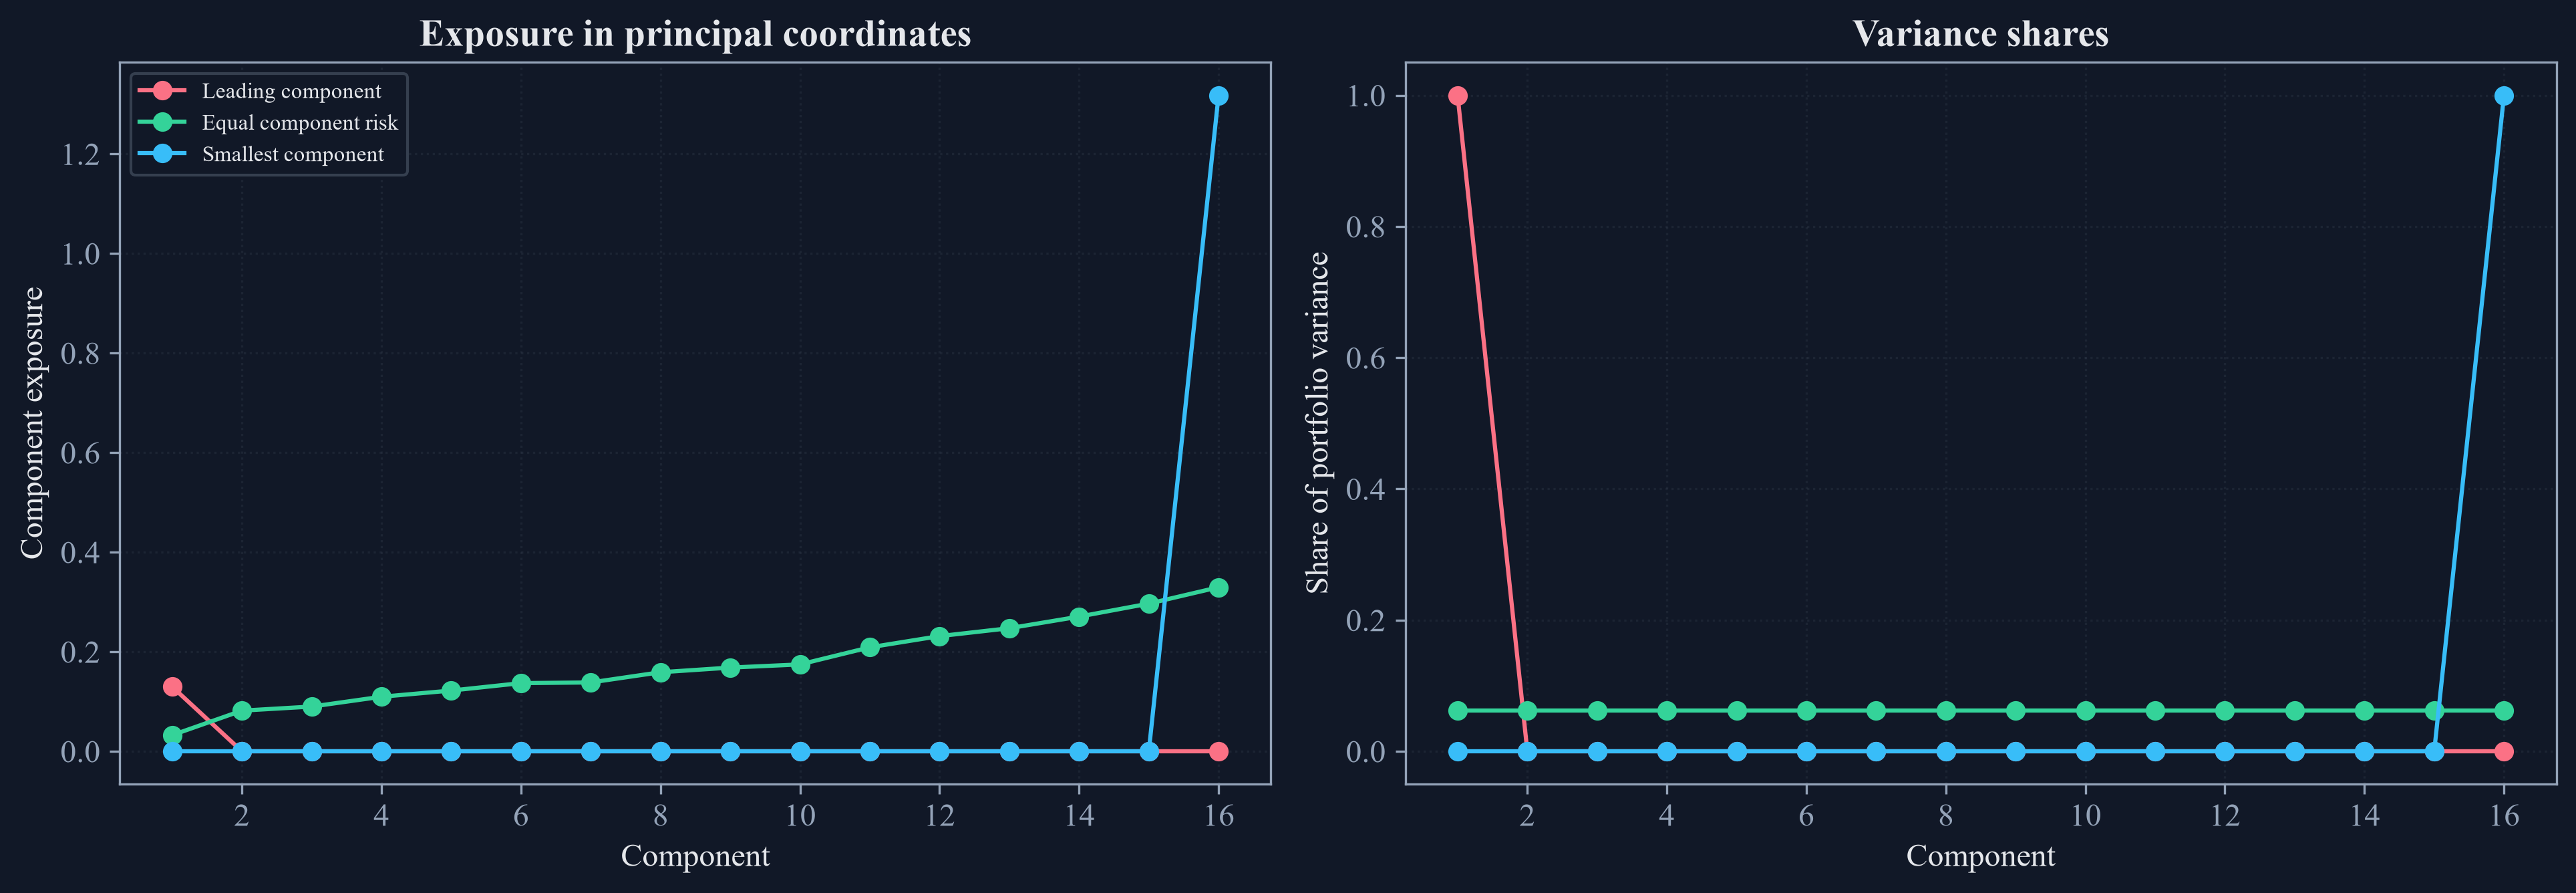

In [3]:
component_rows = []
for name, weights in pca_baskets.items():
    exposures = eigenvectors.T @ weights.to_numpy(dtype=float)
    variances = eigenvalues * exposures ** 2
    for component in range(component_count):
        component_rows.append({"Basket": name, "Component": component + 1, "Eigenvalue": eigenvalues[component], "Component exposure": exposures[component], "Variance contribution": variances[component], "Variance share": variances[component] / variances.sum()})
component_risk = pd.DataFrame(component_rows)
save_table(component_risk, "pca_component_risk", "Principal-component exposures and variance shares.", "tab:chapter22-component-risk")
display(component_risk)

figure, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for name, color in zip(pca_baskets, [palette["rose"], palette["green"], palette["cyan"]]):
    subset = component_risk[component_risk["Basket"] == name]
    axes[0].plot(subset["Component"], subset["Component exposure"], marker="o", label=name, color=color)
    axes[1].plot(subset["Component"], subset["Variance share"], marker="o", label=name, color=color)
axes[0].set_title("Exposure in principal coordinates")
axes[0].set_ylabel("Component exposure")
axes[1].set_title("Variance shares")
axes[1].set_ylabel("Share of portfolio variance")
for axis in axes:
    axis.set_xlabel("Component")
    axis.grid(alpha=0.3)
axes[0].legend(fontsize=8)
figure.tight_layout()
save_figure(figure, "pca_component_exposures")

## Diagnosing hedge contributions

Asset-level variance contribution and correlation with the basket answer different exposure questions:

$$
\operatorname{RC}_i=w_i(\Sigma w)_i,
\qquad
\operatorname{Corr}(r_i,r_w)=\frac{(\Sigma w)_i}{\sqrt{\Sigma_{ii}}\sqrt{w^{\mathsf T}\Sigma w}}.
$$

Here, $w_i$ is the weight of asset $i$, $(\Sigma w)_i$ is its covariance with the basket, $\operatorname{RC}_i$ is its contribution to basket variance, $r_i$ is its return, and $r_w=w^{\mathsf T}r$ is the basket return.

,Basket,Variance,Annual volatility,Net exposure,Gross exposure,Largest absolute weight,Largest absolute variance-contribution share,Largest absolute asset-to-basket correlation
0,Equal weight,0.034531,0.185824,1,1,0.0625,0.09649,0.888332
1,Minimum variance,0.021882,0.147925,1,1.958914,0.489942,0.489942,0.884732
2,Smallest-component gross one,0.001496,0.038682,0.067532,1,0.373984,0.538411,0.333073
3,Smallest-component dollar neutral,0.001606,0.040075,0,1,0.364742,0.716071,0.450654


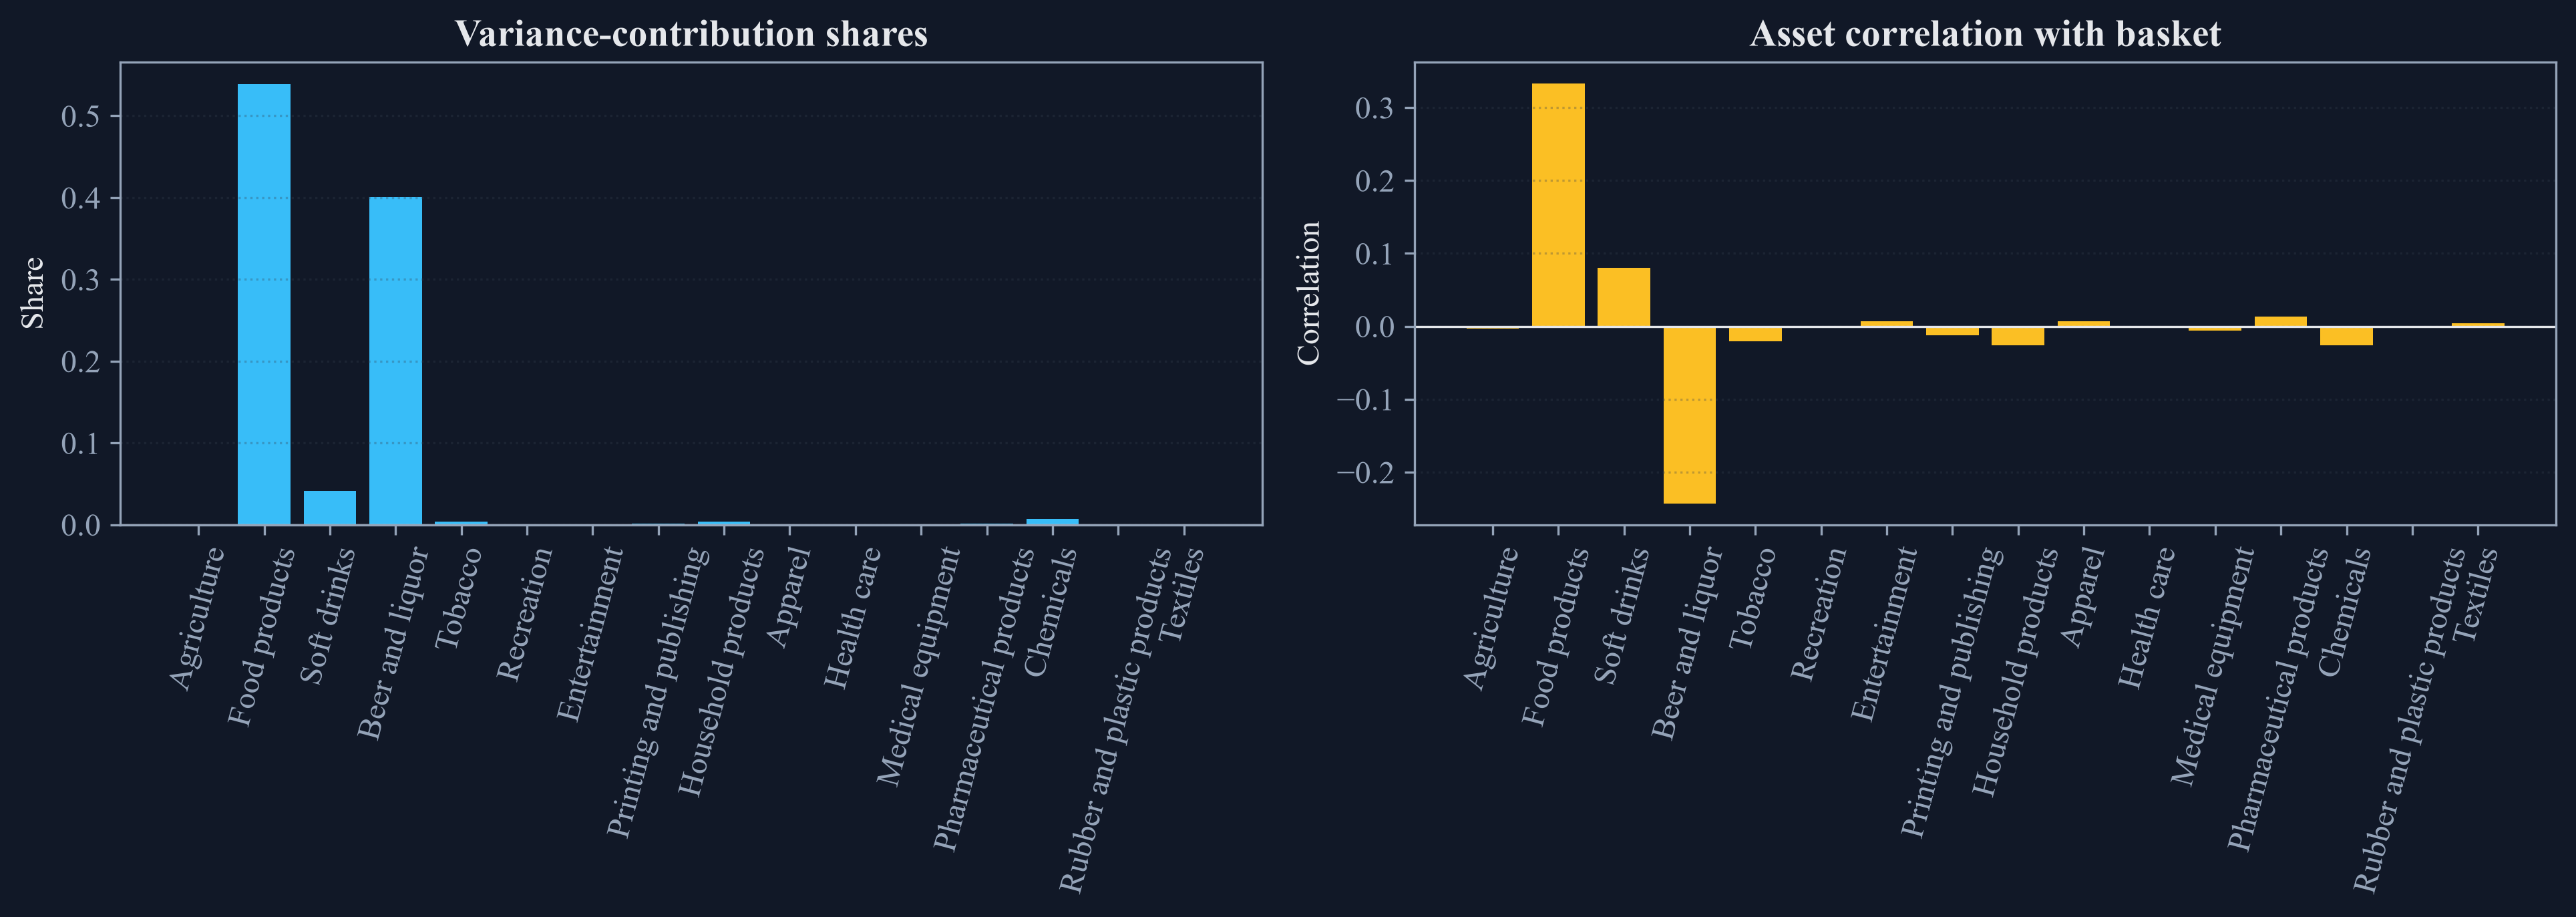

In [4]:
smallest_raw = pca_baskets["Smallest component"]
smallest_gross = smallest_raw / np.abs(smallest_raw).sum()
neutral_values = smallest_gross - smallest_gross.mean()
smallest_neutral = neutral_values / np.abs(neutral_values).sum()
diagnostic_baskets = {"Equal weight": pd.Series(1.0 / len(public_covariance), index=public_covariance.index), "Minimum variance": optimal_series(public_covariance), "Smallest-component gross one": smallest_gross, "Smallest-component dollar neutral": smallest_neutral}
diagnostic_rows = []
asset_rows = []
asset_scales = np.sqrt(np.diag(public_values))
for name, weights in diagnostic_baskets.items():
    vector = weights.reindex(public_covariance.index).to_numpy(dtype=float)
    basket_covariance = public_values @ vector
    variance = float(vector @ basket_covariance)
    risk_contributions = vector * basket_covariance
    correlations = basket_covariance / (asset_scales * np.sqrt(variance))
    diagnostic_rows.append({"Basket": name, "Variance": variance, "Annual volatility": np.sqrt(variance), "Net exposure": float(vector.sum()), "Gross exposure": float(np.abs(vector).sum()), "Largest absolute weight": float(np.abs(vector).max()), "Largest absolute variance-contribution share": float(np.abs(risk_contributions / variance).max()), "Largest absolute asset-to-basket correlation": float(np.abs(correlations).max())})
    for asset, weight, contribution, correlation in zip(public_covariance.index, vector, risk_contributions, correlations):
        asset_rows.append({"Basket": name, "Industry": asset, "Weight": weight, "Variance contribution": contribution, "Variance-contribution share": contribution / variance, "Correlation to basket": correlation})
basket_diagnostics = pd.DataFrame(diagnostic_rows)
asset_diagnostics = pd.DataFrame(asset_rows)
basket_book_diagnostics = basket_diagnostics[["Basket", "Annual volatility", "Net exposure", "Gross exposure", "Largest absolute variance-contribution share", "Largest absolute asset-to-basket correlation"]]
save_table(basket_book_diagnostics, "basket_exposure_diagnostics", "Risk and correlation diagnostics for four public baskets.", "tab:chapter22-basket-diagnostics")
save_table(asset_diagnostics, "asset_exposure_diagnostics", "Asset-level contribution and correlation diagnostics.", "tab:chapter22-asset-diagnostics")
display(basket_diagnostics)

smallest_asset_diagnostics = asset_diagnostics[asset_diagnostics["Basket"] == "Smallest-component gross one"]
figure, axes = plt.subplots(1, 2, figsize=(13, 4.7))
axes[0].bar(smallest_asset_diagnostics["Industry"], smallest_asset_diagnostics["Variance-contribution share"], color=palette["cyan"])
axes[0].set_title("Variance-contribution shares")
axes[0].set_ylabel("Share")
axes[1].bar(smallest_asset_diagnostics["Industry"], smallest_asset_diagnostics["Correlation to basket"], color=palette["amber"])
axes[1].set_title("Asset correlation with basket")
axes[1].set_ylabel("Correlation")
for axis in axes:
    axis.tick_params(axis="x", rotation=75)
    axis.axhline(0.0, color=palette["text"], linewidth=0.8)
    axis.grid(axis="y", alpha=0.3)
figure.tight_layout()
save_figure(figure, "basket_risk_and_correlation")

## Subset Exposure

The correlation between a subset return and the full basket can reveal concentration that individual weights do not show:

$$
\operatorname{Corr}(r_G,r_w)=\frac{u_G^{\mathsf T}\Sigma w}{\sqrt{u_G^{\mathsf T}\Sigma u_G}\sqrt{w^{\mathsf T}\Sigma w}}.
$$

Here, $G$ is a subset of assets, $r$ is the vector of asset returns, $u_G$ is an equal-weight vector supported only on that subset, $r_G=u_G^{\mathsf T}r$ is its return, $w$ is the full basket, $r_w=w^{\mathsf T}r$ is the basket return, and $\Sigma$ is the asset covariance matrix.

,Basket,Cluster,Industries,Mean silhouette value,Subset-to-basket correlation,Cluster variance-contribution share
0,Equal weight,1,10,0.16692,0.97208,0.72974
1,Equal weight,2,6,0.234747,0.83776,0.27026
2,Minimum variance,1,10,0.16692,0.662756,-0.002436
3,Minimum variance,2,6,0.234747,0.925357,1.002436
4,Smallest-component dollar neutral,1,10,0.16692,-0.302877,0.135543
5,Smallest-component dollar neutral,2,6,0.234747,-0.242719,0.864457
6,Smallest-component gross one,1,10,0.16692,-0.002742,0.011
7,Smallest-component gross one,2,6,0.234747,0.016865,0.989


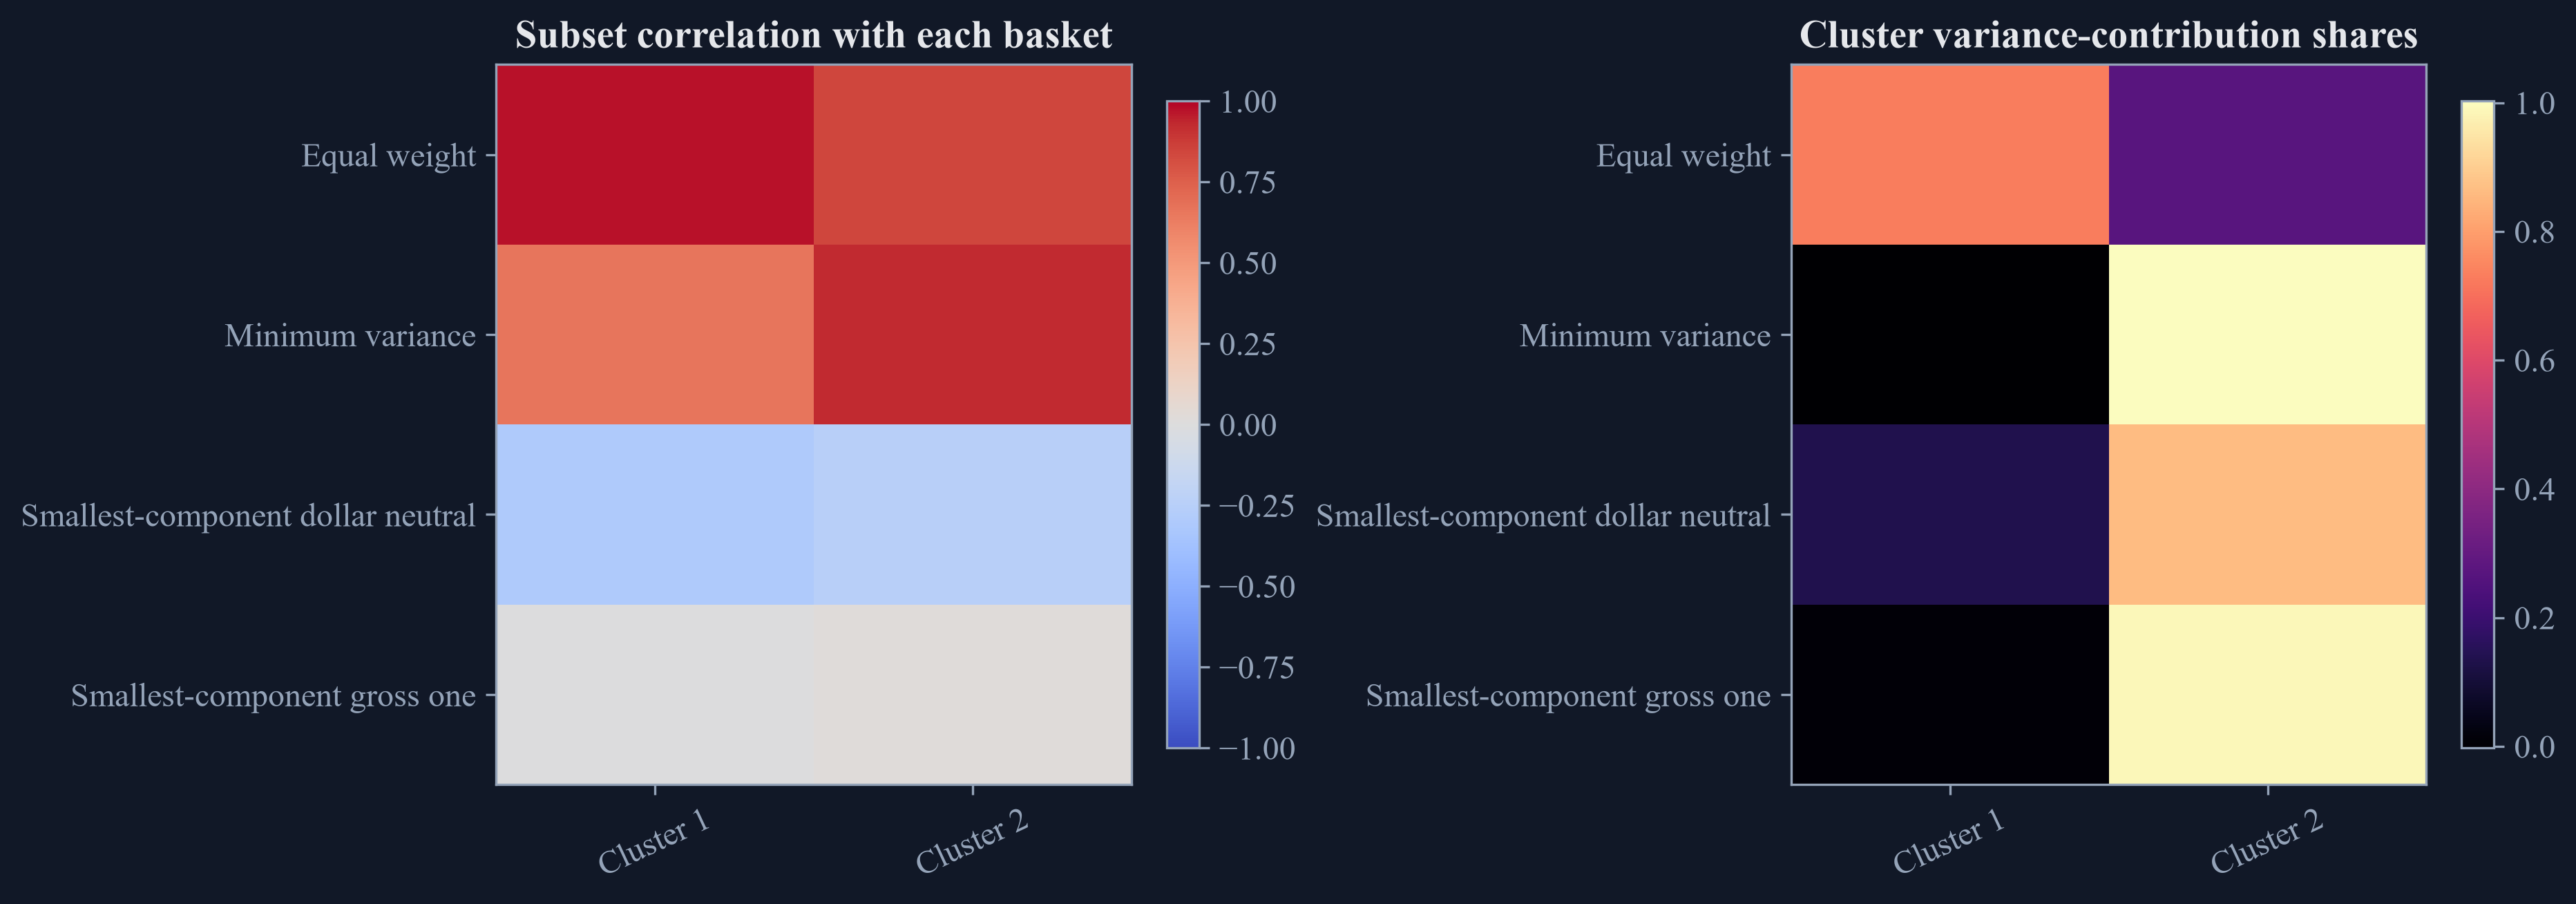

In [5]:
np.random.seed(2260)
_, exposure_clusters, exposure_silhouette = cluster_k_means_base(public_correlation, max_clusters=4, iterations=10)
subset_rows = []
for basket_name, weights in diagnostic_baskets.items():
    vector = weights.reindex(public_covariance.index).to_numpy(dtype=float)
    basket_variance = float(vector @ public_values @ vector)
    marginal = public_values @ vector
    for cluster_id, members in exposure_clusters.items():
        subset_vector = np.zeros(len(public_covariance))
        indices = [public_covariance.index.get_loc(member) for member in members]
        subset_vector[indices] = 1.0 / len(indices)
        subset_variance = float(subset_vector @ public_values @ subset_vector)
        subset_correlation = float(subset_vector @ public_values @ vector / np.sqrt(subset_variance * basket_variance))
        group_contribution = float((vector[indices] * marginal[indices]).sum() / basket_variance)
        subset_rows.append({"Basket": basket_name, "Cluster": int(cluster_id) + 1, "Industries": len(members), "Mean silhouette value": float(exposure_silhouette.loc[members].mean()), "Subset-to-basket correlation": subset_correlation, "Cluster variance-contribution share": group_contribution})
subset_diagnostics = pd.DataFrame(subset_rows).sort_values(["Basket", "Cluster"]).reset_index(drop=True)
subset_book_diagnostics = subset_diagnostics[["Basket", "Cluster", "Industries", "Subset-to-basket correlation", "Cluster variance-contribution share"]].rename(columns={"Subset-to-basket correlation": "Subset correlation", "Cluster variance-contribution share": "Variance share"})
save_table(subset_book_diagnostics, "subset_exposure_diagnostics", "Cluster-subset correlation and variance-contribution diagnostics.", "tab:chapter22-subset-diagnostics")
display(subset_diagnostics)

subset_matrix = subset_diagnostics.pivot(index="Basket", columns="Cluster", values="Subset-to-basket correlation")
figure, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))
first = axes[0].imshow(subset_matrix.to_numpy(dtype=float), vmin=-1.0, vmax=1.0, cmap="coolwarm", aspect="auto")
axes[0].set_xticks(range(len(subset_matrix.columns)))
axes[0].set_xticklabels([f"Cluster {value}" for value in subset_matrix.columns], rotation=25)
axes[0].set_yticks(range(len(subset_matrix.index)))
axes[0].set_yticklabels(subset_matrix.index)
axes[0].set_title("Subset correlation with each basket")
contribution_matrix = subset_diagnostics.pivot(index="Basket", columns="Cluster", values="Cluster variance-contribution share")
second = axes[1].imshow(contribution_matrix.to_numpy(dtype=float), cmap="magma", aspect="auto")
axes[1].set_xticks(range(len(contribution_matrix.columns)))
axes[1].set_xticklabels([f"Cluster {value}" for value in contribution_matrix.columns], rotation=25)
axes[1].set_yticks(range(len(contribution_matrix.index)))
axes[1].set_yticklabels(contribution_matrix.index)
axes[1].set_title("Cluster variance-contribution shares")
figure.colorbar(first, ax=axes[0], fraction=0.046)
figure.colorbar(second, ax=axes[1], fraction=0.046)
figure.tight_layout()
save_figure(figure, "subset_exposure_heatmaps")

## Enforcing hedge position limits

Net exposure, gross exposure, and position bounds constrain different features of a hedge:

$$
E_{\mathrm{net}}=\mathbf 1^{\mathsf T}w,
\qquad
E_{\mathrm{gross}}=\lVert w\rVert_1,
\qquad
\ell_i\leq w_i\leq u_i.
$$

Here, $w$ is the weight vector, $\mathbf 1$ is a vector of ones, $i$ indexes the assets, $E_{\mathrm{net}}$ is long exposure minus short exposure, $E_{\mathrm{gross}}$ is total absolute exposure, and $\ell_i$ and $u_i$ are the lower and upper bounds for asset $i$.

,Basket,Net exposure,Gross exposure,Smallest weight,Largest weight,Annual volatility,Gross exposure at most one,Dollar neutral
0,Risk-targeted smallest component,0.174582,2.585178,-0.834062,0.966816,0.1,No,No
1,Gross-one smallest component,0.067532,1,-0.322632,0.373984,0.038682,Yes,No
2,Dollar-neutral gross-one hedge,0,1,-0.322414,0.364742,0.040075,Yes,Yes


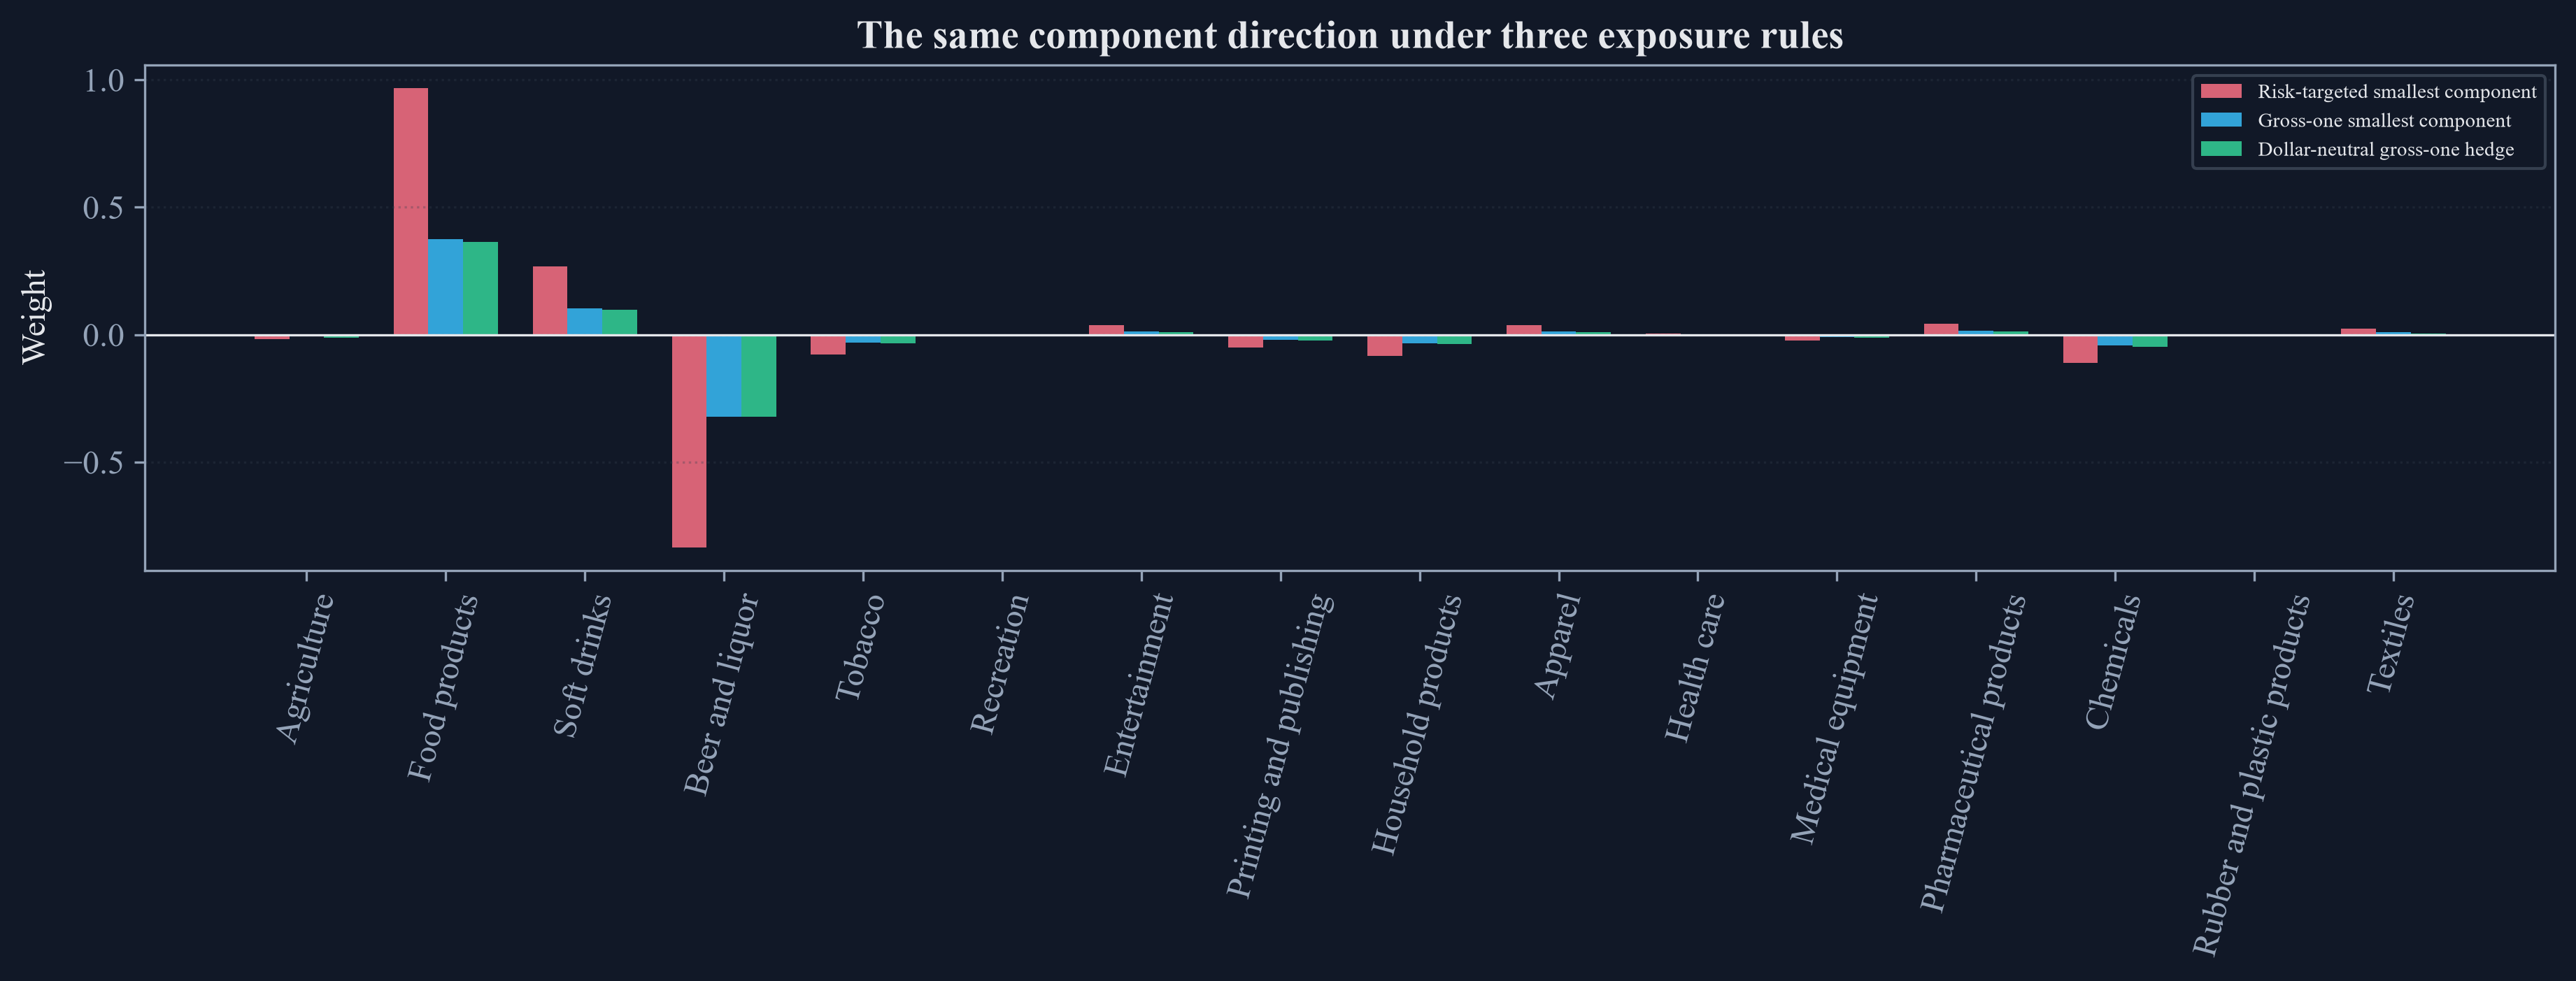

In [6]:
raw_smallest = smallest_raw
gross_one_smallest = smallest_gross
neutral_smallest = smallest_neutral
constraint_baskets = {"Risk-targeted smallest component": raw_smallest, "Gross-one smallest component": gross_one_smallest, "Dollar-neutral gross-one hedge": neutral_smallest}
constraint_rows = []
constraint_weight_rows = []
for name, weights in constraint_baskets.items():
    constraint_rows.append({"Basket": name, "Net exposure": float(weights.sum()), "Gross exposure": float(np.abs(weights).sum()), "Smallest weight": float(weights.min()), "Largest weight": float(weights.max()), "Annual volatility": np.sqrt(portfolio_variance(weights, public_covariance)), "Gross exposure at most one": "Yes" if np.abs(weights).sum() <= 1.0 + 1e-12 else "No", "Dollar neutral": "Yes" if abs(weights.sum()) <= 1e-12 else "No"})
    for asset, weight in weights.items():
        constraint_weight_rows.append({"Basket": name, "Industry": asset, "Weight": weight})
constraint_summary = pd.DataFrame(constraint_rows)
constraint_weights = pd.DataFrame(constraint_weight_rows)
constraint_book_summary = constraint_summary[["Basket", "Net exposure", "Gross exposure", "Smallest weight", "Largest weight", "Annual volatility"]]
save_table(constraint_book_summary, "hedge_constraint_summary", "Net, gross, position, and volatility diagnostics for three hedge scalings.", "tab:chapter22-constraint-summary")
save_table(constraint_weights, "hedge_constraint_weights", "Asset weights under three hedge scalings.", "tab:chapter22-constraint-weights")
display(constraint_summary)

figure, axis = plt.subplots(figsize=(12.5, 4.8))
width = 0.25
positions = np.arange(len(public_covariance))
for offset, (name, color) in enumerate(zip(constraint_baskets, [palette["rose"], palette["cyan"], palette["green"]])):
    axis.bar(positions + (offset - 1) * width, constraint_baskets[name].to_numpy(dtype=float), width=width, label=name, color=color, alpha=0.85)
axis.set_xticks(positions)
axis.set_xticklabels(public_covariance.index, rotation=75)
axis.set_ylabel("Weight")
axis.set_title("The same component direction under three exposure rules")
axis.axhline(0.0, color=palette["text"], linewidth=0.8)
axis.legend(fontsize=7)
axis.grid(axis="y", alpha=0.3)
figure.tight_layout()
save_figure(figure, "net_gross_hedge_weights")

## Rolling Stability

Sign alignment separates the arbitrary sign of an eigenvector from a real change in its direction:

$$
\widetilde v_k=\operatorname{sign}(v_{k-1}^{\mathsf T}v_k)v_k,
\qquad
A_k=|v_{k-1}^{\mathsf T}\widetilde v_k|.
$$

Here, $v_k$ is the smallest-eigenvalue loading vector in window $k$, $\widetilde v_k$ is its sign-aligned version, and $A_k$ is the absolute loading alignment, with one indicating identical directions up to sign.

,Quantity,Value
0,Rolling windows,12
1,Mean absolute loading alignment,0.872601
2,Minimum absolute loading alignment,0.583825
3,Mean one-way weight change,0.29278
4,Maximum one-way weight change,0.557026
5,Mean smallest-eigenvalue gap,0.000939
6,Minimum smallest-eigenvalue gap,0.000108


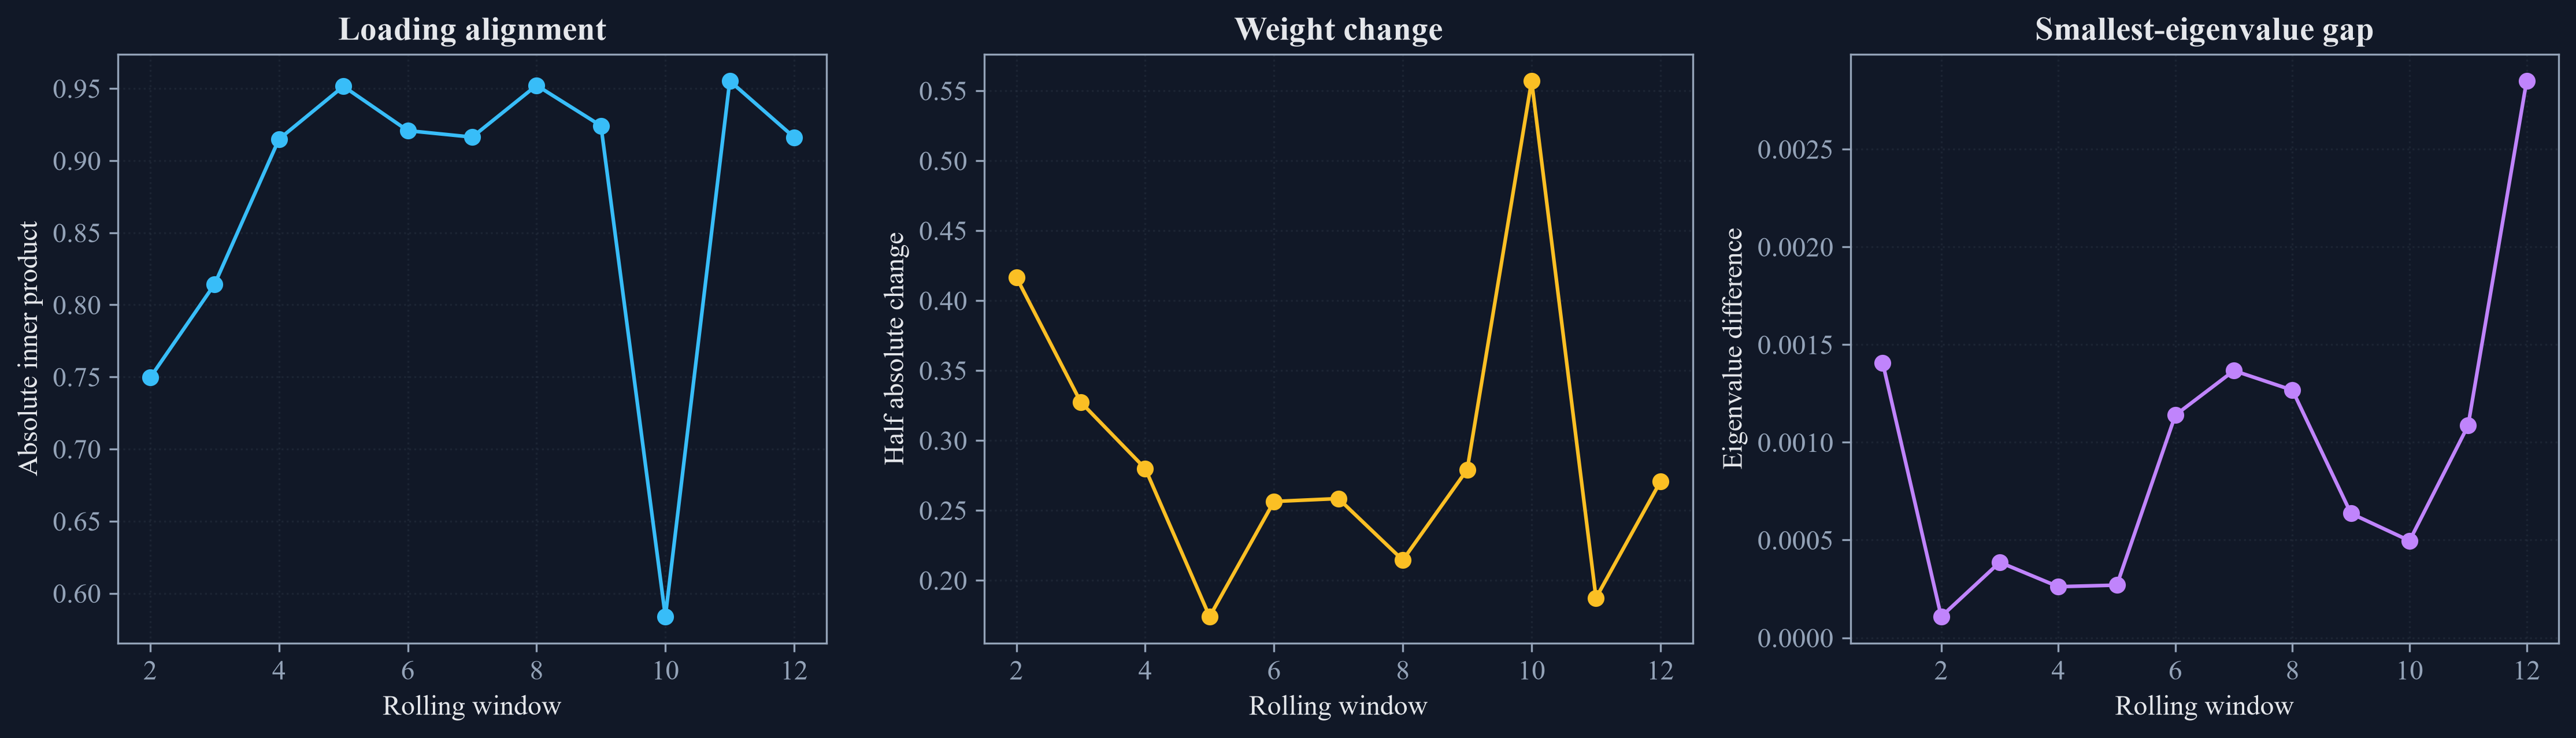

In [7]:
rolling_hedge_rows = []
previous_loading = None
previous_weight = None
hedge_window = 0
for endpoint in range(251, len(public_sample), 126):
    window = public_sample.iloc[endpoint - 251:endpoint + 1]
    covariance = window.cov() * 252.0
    values, vectors = np.linalg.eigh(covariance.to_numpy(dtype=float))
    loading = vectors[:, 0]
    raw_alignment = np.nan if previous_loading is None else float(previous_loading @ loading)
    if previous_loading is not None and raw_alignment < 0.0:
        loading = -loading
    weight = pd.Series(loading / np.abs(loading).sum(), index=covariance.index)
    hedge_window += 1
    rolling_hedge_rows.append({"Window": hedge_window, "Window end": str(window.index[-1].date()), "Smallest eigenvalue": values[0], "Next eigenvalue": values[1], "Smallest-eigenvalue gap": values[1] - values[0], "Absolute loading alignment": np.nan if previous_loading is None else float(abs(previous_loading @ loading)), "One-way weight change": np.nan if previous_weight is None else one_way_turnover(weight, previous_weight), "Net exposure": float(weight.sum()), "Gross exposure": float(np.abs(weight).sum())})
    previous_loading = loading
    previous_weight = weight
rolling_hedge = pd.DataFrame(rolling_hedge_rows)
rolling_hedge_summary = pd.DataFrame({"Quantity": ["Rolling windows", "Mean absolute loading alignment", "Minimum absolute loading alignment", "Mean one-way weight change", "Maximum one-way weight change", "Mean smallest-eigenvalue gap", "Minimum smallest-eigenvalue gap"], "Value": [len(rolling_hedge), rolling_hedge["Absolute loading alignment"].mean(), rolling_hedge["Absolute loading alignment"].min(), rolling_hedge["One-way weight change"].mean(), rolling_hedge["One-way weight change"].max(), rolling_hedge["Smallest-eigenvalue gap"].mean(), rolling_hedge["Smallest-eigenvalue gap"].min()]})
save_table(rolling_hedge, "rolling_pca_hedge_stability", "Rolling public smallest-component hedge diagnostics.", "tab:chapter22-rolling-hedge")
save_table(rolling_hedge_summary, "rolling_pca_hedge_summary", "Summary of rolling public hedge stability.", "tab:chapter22-rolling-hedge-summary")
display(rolling_hedge_summary)

figure, axes = plt.subplots(1, 3, figsize=(15, 4.4))
axes[0].plot(rolling_hedge["Window"], rolling_hedge["Absolute loading alignment"], marker="o", color=palette["cyan"])
axes[0].set_title("Loading alignment")
axes[0].set_ylabel("Absolute inner product")
axes[1].plot(rolling_hedge["Window"], rolling_hedge["One-way weight change"], marker="o", color=palette["amber"])
axes[1].set_title("Weight change")
axes[1].set_ylabel("Half absolute change")
axes[2].plot(rolling_hedge["Window"], rolling_hedge["Smallest-eigenvalue gap"], marker="o", color=palette["violet"])
axes[2].set_title("Smallest-eigenvalue gap")
axes[2].set_ylabel("Eigenvalue difference")
for axis in axes:
    axis.set_xlabel("Rolling window")
    axis.grid(alpha=0.3)
figure.tight_layout()
save_figure(figure, "rolling_pca_hedge_stability")

## Calculation Checks

When the component-risk shares sum to one, the implemented scaling gives the requested variance exactly up to numerical precision:

$$
w^{\mathsf T}\Sigma w=s^2\sum_{k=1}^{N}\rho_k=s^2.
$$

Here, $w$ is the principal-component weight vector, $s$ is the requested standard deviation, $\rho_k$ is the risk share of component $k$, $N$ is the number of components, and $\Sigma$ is the covariance matrix.

In [8]:
test_covariance = np.array([[1.0, 1.0], [1.0, 4.0]])
default_test_weights = pca_weights(test_covariance, risk_distribution=None, risk_target=1.0)
explicit_test_weights = pca_weights(test_covariance, risk_distribution=np.array([0.0, 1.0]), risk_target=1.0)
public_direct_weights = pca_baskets["Smallest component"].to_numpy(dtype=float)
public_library_weights = library_pca_baskets["Smallest component"].to_numpy(dtype=float)
direction_difference = min(float(np.max(np.abs(public_direct_weights - public_library_weights))), float(np.max(np.abs(public_direct_weights + public_library_weights))))
released_checks = pd.DataFrame({"Check": ["Two-asset default variance", "Two-asset explicit smallest-component variance", "Default and explicit weight difference", "Public direct and library direction difference", "Public requested variance", "Public realized variance"], "Value": [float(default_test_weights @ test_covariance @ default_test_weights), float(explicit_test_weights @ test_covariance @ explicit_test_weights), float(np.max(np.abs(default_test_weights - explicit_test_weights))), direction_difference, target_standard_deviation ** 2, portfolio_variance(pca_baskets["Smallest component"], public_covariance)]})
preliminary_hedging_parity = pd.DataFrame({"Preliminary or library item": ["PCA minimum-variance component weights", "Alternative component-risk distribution", "Target-variance identity", "Two-asset calculation check", "Asset contribution to risk", "Asset correlation to basket", "Subset correlation to basket", "Net and gross exposure checks", "Rolling loading stability"], "Chapter 22 location": ["Section 22.3"] * 9, "Status": ["Included"] * 9})
hedging_section_summary = pd.DataFrame({"Quantity": ["Public observations", "Selected industries", "Principal components", "Risk distributions", "Diagnostic baskets", "Detected exposure clusters", "Rolling hedge windows"], "Value": [len(public_sample), len(public_covariance), component_count, len(risk_distributions), len(diagnostic_baskets), len(exposure_clusters), len(rolling_hedge)]})
save_table(released_checks, "released_pca_weight_checks", "Direct checks of the principal-component weight calculation.", "tab:chapter22-released-pca-checks")
save_table(preliminary_hedging_parity, "preliminary_hedging_parity", "Coverage of hedge calculations and diagnostics.", "tab:chapter22-hedging-parity")
save_table(hedging_section_summary, "hedging_section_summary", "Section 22.3 numerical summary.", "tab:chapter22-hedging-section-summary")
display(released_checks)
display(preliminary_hedging_parity)
display(hedging_section_summary)

,Check,Value
0,Two-asset default variance,1
1,Two-asset explicit smallest-component variance,1
2,Default and explicit weight difference,0
3,Public direct and library direction difference,0
4,Public requested variance,0.01
5,Public realized variance,0.01


,Preliminary or library item,Chapter 22 location,Status
0,PCA minimum-variance component weights,Section 22.3,Included
1,Alternative component-risk distribution,Section 22.3,Included
2,Target-variance identity,Section 22.3,Included
3,Two-asset calculation check,Section 22.3,Included
4,Asset contribution to risk,Section 22.3,Included
5,Asset correlation to basket,Section 22.3,Included
6,Subset correlation to basket,Section 22.3,Included
7,Net and gross exposure checks,Section 22.3,Included
8,Rolling loading stability,Section 22.3,Included


,Quantity,Value
0,Public observations,1760
1,Selected industries,16
2,Principal components,16
3,Risk distributions,3
4,Diagnostic baskets,4
5,Detected exposure clusters,2
6,Rolling hedge windows,12


## Tests

In [9]:
assert public_sample.shape == (1760, 16)
assert np.all(eigenvalues > 0.0)
assert np.all(np.diff(eigenvalues) <= 0.0)
assert np.isclose(explained_variance.sum(), 1.0)
assert np.isclose(cumulative_variance[-1], 1.0)
assert set(pca_baskets) == {'Leading component', 'Equal component risk', 'Smallest component'}
assert np.allclose(pca_target_summary['Realized standard deviation'], target_standard_deviation)
assert np.allclose(pca_target_summary['Largest component variance share'].to_numpy()[[0, 2]], 1.0)
assert len(pca_weight_table) == 3 * component_count
assert len(component_risk) == 3 * component_count
assert np.allclose(component_risk.groupby('Basket')['Variance share'].sum(), 1.0)
assert len(basket_diagnostics) == 4
assert len(asset_diagnostics) == 4 * component_count
assert np.allclose(asset_diagnostics.groupby('Basket')['Variance-contribution share'].sum(), 1.0)
assert asset_diagnostics['Correlation to basket'].between(-1.0 - 1e-12, 1.0 + 1e-12).all()
assert 2 <= len(exposure_clusters) <= 4
assert len(subset_diagnostics) == len(diagnostic_baskets) * len(exposure_clusters)
assert subset_diagnostics['Subset-to-basket correlation'].between(-1.0 - 1e-12, 1.0 + 1e-12).all()
assert np.allclose(subset_diagnostics.groupby('Basket')['Cluster variance-contribution share'].sum(), 1.0)
assert np.isclose(np.abs(gross_one_smallest).sum(), 1.0)
assert np.isclose(np.abs(neutral_smallest).sum(), 1.0)
assert np.isclose(neutral_smallest.sum(), 0.0, atol=1e-12)
assert len(constraint_summary) == 3
assert len(rolling_hedge) >= 10
assert rolling_hedge['Absolute loading alignment'].dropna().between(0.0, 1.0 + 1e-12).all()
assert rolling_hedge['One-way weight change'].dropna().ge(0.0).all()
assert rolling_hedge['Smallest-eigenvalue gap'].gt(0.0).all()
assert np.allclose(rolling_hedge['Gross exposure'], 1.0)
assert np.isclose(default_test_weights @ test_covariance @ default_test_weights, 1.0)
assert np.isclose(explicit_test_weights @ test_covariance @ explicit_test_weights, 1.0)
assert np.allclose(default_test_weights, explicit_test_weights)
assert released_checks['Value'].iloc[2] < 1e-12
assert released_checks['Value'].iloc[3] < 1e-12
assert np.isclose(released_checks['Value'].iloc[4], released_checks['Value'].iloc[5])
assert len(preliminary_hedging_parity) == 9
assert preliminary_hedging_parity['Status'].eq('Included').all()
assert len(hedging_section_summary) == 7
assert (FIGURES / 'public_pca_spectrum_loadings.pdf').is_file()
assert (FIGURES / 'pca_weight_profiles.pdf').is_file()
assert (FIGURES / 'pca_component_exposures.pdf').is_file()
assert (FIGURES / 'basket_risk_and_correlation.pdf').is_file()
assert (FIGURES / 'subset_exposure_heatmaps.pdf').is_file()
assert (FIGURES / 'net_gross_hedge_weights.pdf').is_file()
assert (FIGURES / 'rolling_pca_hedge_stability.pdf').is_file()
assert (TABLES / 'released_pca_weight_checks.tex').is_file()
